In [37]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv


In [38]:
load_dotenv()
model = ChatGroq(model="openai/gpt-oss-20b")

In [39]:
class BlogState(TypedDict):
    title: str
    outline: str
    content: str
    evaluation: str

In [40]:
def create_outline(state: BlogState)-> BlogState:
    title = state['title']
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content
    state['outline'] = outline
    return state

In [41]:
def create_blog(state: BlogState)-> BlogState:
    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the following outline \n {outline}'

    content = model.invoke(prompt).content

    state['content']= content
    return state

In [42]:
def evaluation_blog(state:BlogState)-> BlogState:
    outline = state['outline']
    content = state['content']
    prompt = f' Based on my outline -{outline} and my blog - {content}, rate my Blog out of 10.'

    evaluation = model.invoke(prompt).content
    state['evaluation'] = evaluation
    return state

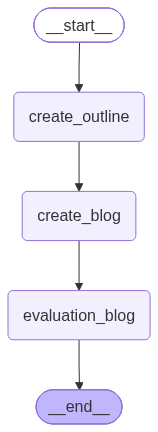

In [43]:
graph = StateGraph(BlogState)

graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)
graph.add_node('evaluation_blog', evaluation_blog)

graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', 'evaluation_blog')
graph.add_edge('evaluation_blog', END)
workflow = graph.compile()
workflow


In [44]:
initial_state = {'title': 'Rise of AI in India'}
final_state = workflow.invoke(initial_state)
print(final_state)


{'title': 'Rise of AI in India', 'outline': '**Blog Title:**  \n**“The Rise of AI in India: From Startups to Super‑Duper‑Data”**\n\n---\n\n## 1. Introduction  \n- **Hook:** A quick anecdote or statistic that shows how AI is already reshaping everyday life in India (e.g., 70\u202f% of Indian startups now use AI).  \n- **Purpose:** Explain why the rise of AI matters – economic growth, job creation, societal impact.  \n- **Scope of the post:** What you’ll cover – history, current landscape, policy, success stories, challenges, and future prospects.\n\n---\n\n## 2. Historical Context: AI in India – A Brief Timeline  \n| Year | Milestone | Significance |\n|------|-----------|--------------|\n| **1960s‑70s** | Early AI research in IITs & CSIR labs | Foundations of Indian AI talent pool |\n| **1995** | First AI conference (AIC) | Growing academic interest |\n| **2000s** | AI in defense & space (ISRO, DRDO) | Government adoption |\n| **2015** | “AI for All” initiative | National policy focus |

In [45]:
print(final_state['outline'])

**Blog Title:**  
**“The Rise of AI in India: From Startups to Super‑Duper‑Data”**

---

## 1. Introduction  
- **Hook:** A quick anecdote or statistic that shows how AI is already reshaping everyday life in India (e.g., 70 % of Indian startups now use AI).  
- **Purpose:** Explain why the rise of AI matters – economic growth, job creation, societal impact.  
- **Scope of the post:** What you’ll cover – history, current landscape, policy, success stories, challenges, and future prospects.

---

## 2. Historical Context: AI in India – A Brief Timeline  
| Year | Milestone | Significance |
|------|-----------|--------------|
| **1960s‑70s** | Early AI research in IITs & CSIR labs | Foundations of Indian AI talent pool |
| **1995** | First AI conference (AIC) | Growing academic interest |
| **2000s** | AI in defense & space (ISRO, DRDO) | Government adoption |
| **2015** | “AI for All” initiative | National policy focus |
| **2020‑22** | AI‑driven COVID‑19 response | Proof‑of‑concept at s

In [46]:
print(final_state['content'])

# The Rise of AI in India: From Startups to Super‑Duper‑Data  

---

## 1. Introduction  

Imagine walking into a grocery store in Mumbai and having a virtual assistant that can spot the best‑priced fresh produce, recommend recipes based on what you already own, and even alert you about a potential food‑borne illness before you finish the meal. That’s not science fiction—it’s a glimpse of the AI‑powered world that is already unfolding across India.  

> **Did you know?** 70 % of Indian startups now incorporate AI in at least one product or service.  

AI is no longer a niche technology; it’s a catalyst for economic growth, job creation, and societal transformation. In a country of 1.4 billion people, AI can unlock new productivity gains, democratize access to services, and help solve some of the most pressing challenges—from rural health to climate resilience.  

This post takes you on a journey through the history, current landscape, policy backdrop, success stories, challenges, and f

In [47]:
print(final_state['evaluation'])

**Overall rating: 7.8 / 10**

Your draft is a solid, data‑rich foundation that covers almost every angle of India’s AI story. Below is a quick “what‑works” / “what‑could‑be‑better” snapshot, followed by a handful of concrete suggestions to push it from a great informational piece to a truly compelling, share‑worthy blog post.

---

## What’s Working Well

| Element | Why it’s great |
|---------|----------------|
| **Clear, modular structure** – The 12‑point outline keeps readers oriented and makes the post easy to skim. |
| **Heavy use of tables & timelines** – The visual hooks (e.g., the milestone timeline, sector‑impact matrix) instantly convey complex data. |
| **Strong data points** – Figures such as “70 % of Indian startups use AI” and “₹25 trillion GDP impact” give the narrative weight. |
| **Balanced coverage** – You hit history, policy, talent, sectors, startups, academia, ethics, and the future in a single narrative arc. |
| **Actionable CTA** – The “Call to Action” section tu